# Imports

In [183]:
import os
# I need this to run torch on my computer, comment it according to your GPU, please do not delete, comment ~Omar
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "11.0.0"

In [184]:
from pathlib import Path
import matplotlib.pyplot as plt

## Verify Torch is working

# Data Preparation

## Loading the Dataset

In [185]:
notebook_folderPath = Path().absolute()
print(notebook_folderPath.parent)

/home/omarriad/Documents/10th Sem/DMET 1067 - Deep Learning in Computer Vision/Project Milestone 2/Model Fine-tuning/Models Workspaces


In [186]:
from datasets import Dataset, DatasetDict, load_from_disk
from dataset_preparer import load_and_split_dataset, LazyLoadingImageDataset

dataset_object_filepath = notebook_folderPath / "input"
dataset_source_folderpath = notebook_folderPath.parent.parent / "Datasets - Unsplit" / "X-Ray Region Classification"
labels = None #Loads all when set to None

dataset_augmentation_params = {
    "target_count_per_label": 3000,
    "rotation_min": 50,
    "rotation_max": 120,
    "flipping_chance": 0.25,
    "inverting": True,
    "shift_range": 0.1
}

if (dataset_object_filepath / "dataset_dict.json").is_file():
    print("Dataset Already Loaded, skipping split...")
    dataset = load_from_disk(str(dataset_object_filepath))
else:
    dataset = load_and_split_dataset(labels, dataset_source_folderpath, augmentation_params=dataset_augmentation_params)
    print("Dataset instance created...\nSaving Dataset Object for Future Use...")
    dataset.save_to_disk(str(dataset_object_filepath))

total_samples = sum(len(dataset[split]) for split in dataset.keys())
print("\nData Split by Percentage:")
for split in dataset.keys():
    num_samples = len(dataset[split])
    percentage = (num_samples / total_samples) * 100
    print(f"{split}: {num_samples} samples ({percentage:.2f}%)")

dataset

Dataset Already Loaded, skipping split...

Data Split by Percentage:
train: 18900 samples (70.00%)
validation: 5400 samples (20.00%)
test: 2700 samples (10.00%)


DatasetDict({
    train: Dataset({
        features: ['image_with_augmentation_params', 'label'],
        num_rows: 18900
    })
    validation: Dataset({
        features: ['image_with_augmentation_params', 'label'],
        num_rows: 5400
    })
    test: Dataset({
        features: ['image_with_augmentation_params', 'label'],
        num_rows: 2700
    })
})

In [187]:
unique_labels = set()

for row in dataset["train"]:
    unique_labels.add(row["label"])

unique_labels

{'Chest',
 'Elbow',
 'Finger',
 'Forearm',
 'Hand',
 'Humerus',
 'Shoulder',
 'Tibia_and_Fibula',
 'Wrist'}

In [188]:
dataset["train"] = LazyLoadingImageDataset(dataset["train"], size=(224, 224), padding=True)
dataset["validation"] = LazyLoadingImageDataset(dataset["validation"], size=(224, 224), padding=True)
dataset["test"] = LazyLoadingImageDataset(dataset["test"], size=(224, 224), padding=True)

## Sample Image

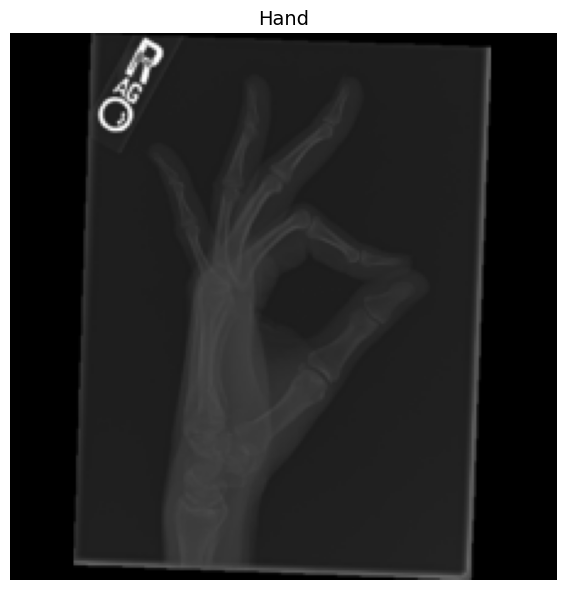

In [189]:
def plot_image_entry(entry):
    """
    Plot an image from a dataset entry with the label as title.
    
    Args:
        entry: Dictionary with 'image' and 'label' keys
    """
    image = entry["image"]
    label = entry["label"]
    
    plt.figure(figsize=(6, 6))
    plt.imshow(image, cmap='gray')
    plt.title(label, fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

plot_image_entry(dataset["train"][18000])

# The model

## Loading the model

In [190]:
from transformers import AutoModelForImageClassification, AutoImageProcessor, MobileNetV2Config

image_processor = AutoImageProcessor.from_pretrained("google/mobilenet_v2_1.0_224") # Normalizes pixels and converts to tensors, image already resized by preparer

# CRITICAL: Sort labels to ensure consistent ordering (not relying on set iteration order)
id2label = {i: label for i, label in enumerate(sorted(unique_labels))}
label2id = {label: i for i, label in enumerate(sorted(unique_labels))}
problem_type = "single_label_classification"

config = MobileNetV2Config.from_pretrained("google/mobilenet_v2_1.0_224", 
                                           id2label=id2label, 
                                           label2id=label2id, 
                                           num_labels=len(unique_labels), 
                                           problem_type=problem_type,
                                           )

model = AutoModelForImageClassification.from_pretrained("google/mobilenet_v2_1.0_224", config=config, ignore_mismatched_sizes=True) # The model itself
print(f"Label mapping: {id2label}")
print(f"Label mapping (reverse): {label2id}")

You passed `num_labels=9` which is incompatible to the `id2label` map of length `1001`.
Loading weights: 100%|██████████| 314/314 [00:00<00:00, 10958.66it/s]
MobileNetV2ForImageClassification LOAD REPORT from: google/mobilenet_v2_1.0_224
Key               | Status   |                                                                                            
------------------+----------+--------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1001, 1280]) vs model:torch.Size([9, 1280])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1001]) vs model:torch.Size([9])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Label mapping: {0: 'Chest', 1: 'Elbow', 2: 'Finger', 3: 'Forearm', 4: 'Hand', 5: 'Humerus', 6: 'Shoulder', 7: 'Tibia_and_Fibula', 8: 'Wrist'}
Label mapping (reverse): {'Chest': 0, 'Elbow': 1, 'Finger': 2, 'Forearm': 3, 'Hand': 4, 'Humerus': 5, 'Shoulder': 6, 'Tibia_and_Fibula': 7, 'Wrist': 8}


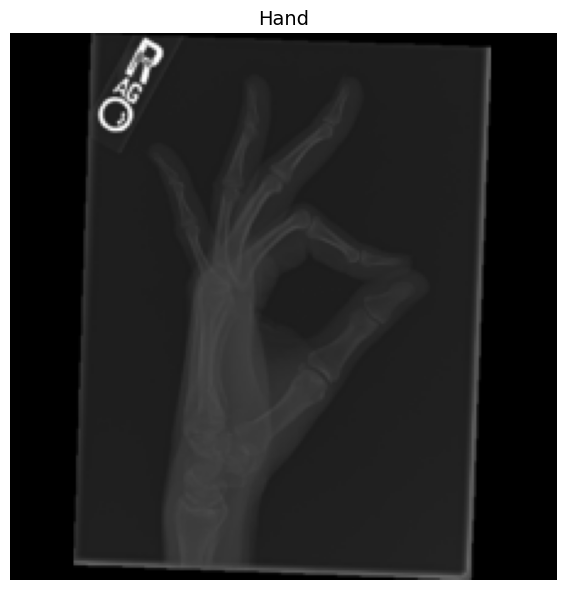

Predicted label: Chest (ID: 0)


In [191]:
import torch
from torch import cuda

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

test_image_entry = dataset["train"][18000]

plot_image_entry(test_image_entry)

# Test with 1 image
model.eval()
with torch.no_grad():
    pixel_values = image_processor(test_image_entry["image"], return_tensors="pt")["pixel_values"].to(device)
    outputs = model(pixel_values)
    predicted_label_id = outputs.logits.argmax(-1).item()
    predicted_label = id2label[predicted_label_id]
    print(f"Predicted label: {predicted_label} (ID: {predicted_label_id})")



## Model Hyperparameters

In [192]:
# Device configuration
DATALOADER_NUM_WORKERS = 2 # If memory issue, decrease. If training is too slow, increase.
PIN_MEMORY = cuda.is_available()


# Model hyperparameters
EPOCHS = 50 # If overfitting, decrease. If underfitting, increase.
WARMUP_STEPS = 300 # If overfitting, increase. If underfitting, decrease.
GRADIENT_ACCUMULATION_STEPS = 1 # If memory issue, increase
BATCH_SIZE = 32 # If memory issue, decrease
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 3e-4 
EARLY_STOPPING_PATIENCE = 12

## Training Setup

In [193]:
import numpy as np
from torch.utils.data import DataLoader

def collate_fn(batch):
    images = [item['image'] for item in batch]
    labels = torch.tensor([label2id[item['label']] for item in batch], dtype=torch.long)
    
    # Process only the batch images (not entire dataset)
    pixel_values = image_processor(images=images, return_tensors="pt")['pixel_values']
    
    return {
        'pixel_values': pixel_values,
        'labels': labels
    }

# Create PyTorch DataLoaders with lazy-loading (no upfront preprocessing!)
train_dataloader = DataLoader(
    dataset["train"],
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=DATALOADER_NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_dataloader = DataLoader(
    dataset["validation"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=DATALOADER_NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_dataloader = DataLoader(
    dataset["test"],
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=DATALOADER_NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

In [194]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
train_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_dataloader))

warmup_scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, 
                                                     start_factor=0.1, 
                                                     total_iters=WARMUP_STEPS
                                                     )

combined_scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, 
                                                           schedulers=[warmup_scheduler, train_scheduler], 
                                                           milestones=[WARMUP_STEPS])

In [195]:
# raise Exception("Execution Stopped, Data Loaded, go to testing.")

## Training Loop

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from tqdm import tqdm
import json

checkpoint_dir = notebook_folderPath / "output" / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

final_model_dir = notebook_folderPath / "output" / "final_model"
final_model_dir.mkdir(parents=True, exist_ok=True)

logs_path = checkpoint_dir / f"training_logs.json"
if logs_path.is_file():
    with open(logs_path, 'r') as f:
        training_logs = json.load(f)
else:
    training_logs = []

total_steps = EPOCHS * len(train_dataloader)
checkpoint_interval = 5

patience_counter = 0

# Resume from latest checkpoint if it exists
checkpoints = sorted(checkpoint_dir.glob("checkpoint_epoch_*.pt"))
if checkpoints:
    latest_checkpoint = checkpoints[-1]
    print(f"Loading checkpoint: {latest_checkpoint}")
    checkpoint = torch.load(latest_checkpoint, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    combined_scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    global_step = checkpoint['epoch'] * len(train_dataloader)
    start_epoch = checkpoint['epoch'] + 1
    print(f"Resumed from epoch {checkpoint['epoch']}, global_step={global_step}")
else:
    start_epoch = 1

best_val_loss = float('inf')
best_model_epoch = 0

best_checkpoint_path = checkpoint_dir / f"best_model_yet.pt"

for epoch in tqdm(range(start_epoch, EPOCHS + 1), desc="Training Progress"):
    model.train()
    correct = 0
    total = 0
    train_loss = 0.0
    # Training loop & gradient accumulation
    step = 0
    patience_counter += 1
    for batch in train_dataloader:
        pixel_values = batch['pixel_values'].to(device)
        labels = batch['labels'].to(device)
        
        outputs = model(pixel_values=pixel_values, labels=labels)
        loss = outputs.loss
        logits = outputs.logits
        
        loss.backward()
        train_loss += loss.item()
        
        if (step + 1) % GRADIENT_ACCUMULATION_STEPS == 0:
            optimizer.step()
            optimizer.zero_grad()

        combined_scheduler.step()
        
        
        _, predicted = torch.max(logits, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

        step += 1
        
    train_accuracy = correct / total
    avg_train_loss = train_loss / len(train_dataloader)
    
    # store checkpoints
    if epoch % checkpoint_interval == 0:
        checkpoint_path = checkpoint_dir / f"checkpoint_epoch_{epoch}.pt"
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': combined_scheduler.state_dict(),
        }, checkpoint_path)
    
    # Validation loop
    model.eval()
    correct = 0
    total = 0
    val_loss = 0.0
    with torch.no_grad():
        for batch in val_dataloader:
            pixel_values = batch['pixel_values'].to(device)
            labels = batch['labels'].to(device)
            
            outputs = model(pixel_values=pixel_values, labels=labels)
            logits = outputs.logits
            loss = outputs.loss
            
            val_loss += loss.item()
            _, predicted = torch.max(logits, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    val_accuracy = correct / total
    avg_val_loss = val_loss / len(val_dataloader)

    # update best model if validation loss improved
    if avg_val_loss < best_val_loss:
        patience_counter = 0
        best_val_loss = avg_val_loss
        best_model_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': combined_scheduler.state_dict(),
        }, best_checkpoint_path)
    
    # Log metrics
    training_logs.append({
        'epoch': epoch,
        'train_loss': avg_train_loss,
        'train_accuracy': train_accuracy,
        'val_loss': avg_val_loss,
        'val_accuracy': val_accuracy
    })

    # save training logs after each epoch
    with open(logs_path, 'w') as f:
        json.dump(training_logs, f, indent=2)

    if patience_counter >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping triggered at epoch {epoch} due to no improvement in validation loss for {EARLY_STOPPING_PATIENCE} consecutive epochs.")
        break


# load best model for testing
best_checkpoint = torch.load(best_checkpoint_path, map_location=device)
model.load_state_dict(best_checkpoint['model_state_dict'])

# Save final model
print("\nTraining complete! Saving final model...")
model.save_pretrained(str(final_model_dir))
image_processor.save_pretrained(str(final_model_dir))

with open(logs_path, 'w') as f:
    json.dump(training_logs, f, indent=2)
print(f"Model saved to {final_model_dir}")
print(f"Training logs saved to {logs_path}")

Training Progress:  34%|███▍      | 17/50 [34:09<1:06:31, 120.96s/it]

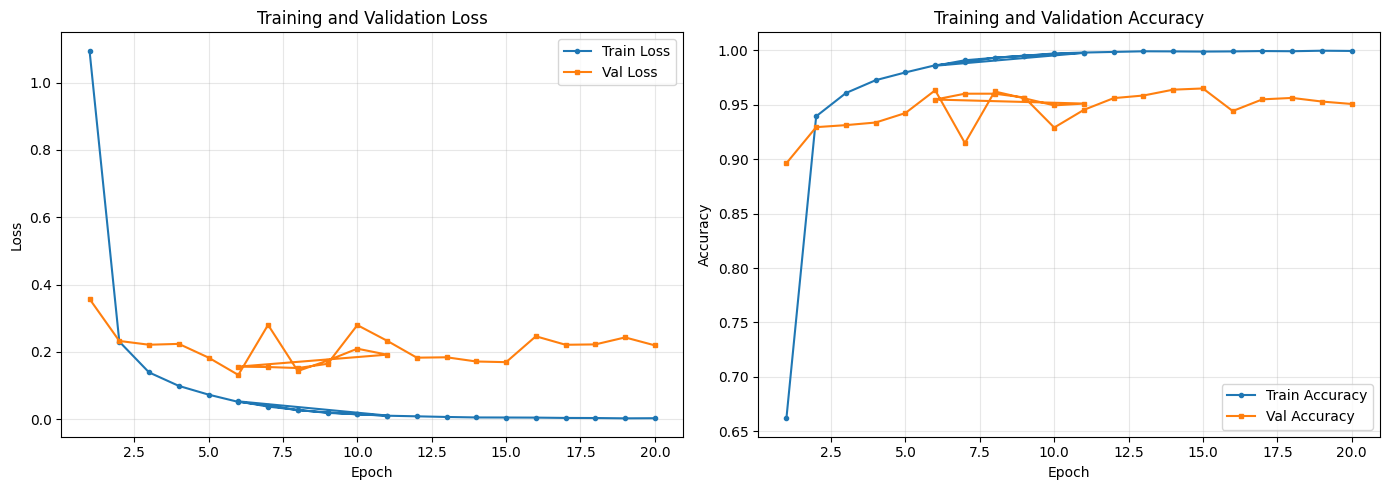

Best Val Accuracy: 0.9650 at Epoch 15
Best Val Loss: 0.1314 at Epoch 6


In [ ]:
# Plot training metrics
import matplotlib.pyplot as plt

epochs = [log['epoch'] for log in training_logs]
train_losses = [log['train_loss'] for log in training_logs]
val_losses = [log['val_loss'] for log in training_logs]
train_accs = [log['train_accuracy'] for log in training_logs]
val_accs = [log['val_accuracy'] for log in training_logs]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot loss
axes[0].plot(epochs, train_losses, label='Train Loss', marker='o', markersize=3)
axes[0].plot(epochs, val_losses, label='Val Loss', marker='s', markersize=3)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot accuracy
axes[1].plot(epochs, train_accs, label='Train Accuracy', marker='o', markersize=3)
axes[1].plot(epochs, val_accs, label='Val Accuracy', marker='s', markersize=3)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Best Val Accuracy: {max(val_accs):.4f} at Epoch {epochs[val_accs.index(max(val_accs))]}")
print(f"Best Val Loss: {min(val_losses):.4f} at Epoch {epochs[val_losses.index(min(val_losses))]}")

## Run on Test set

Class Distribution:

Class                Train           Val             Test           
Chest                2100   ( 11.1%) 600    ( 11.1%) 300    ( 11.1%)
Elbow                2100   ( 11.1%) 600    ( 11.1%) 300    ( 11.1%)
Finger               2100   ( 11.1%) 600    ( 11.1%) 300    ( 11.1%)
Forearm              2100   ( 11.1%) 600    ( 11.1%) 300    ( 11.1%)
Hand                 2100   ( 11.1%) 600    ( 11.1%) 300    ( 11.1%)
Humerus              2100   ( 11.1%) 600    ( 11.1%) 300    ( 11.1%)
Shoulder             2100   ( 11.1%) 600    ( 11.1%) 300    ( 11.1%)
Tibia_and_Fibula     2100   ( 11.1%) 600    ( 11.1%) 300    ( 11.1%)
Wrist                2100   ( 11.1%) 600    ( 11.1%) 300    ( 11.1%)

Sampling test images from each class...


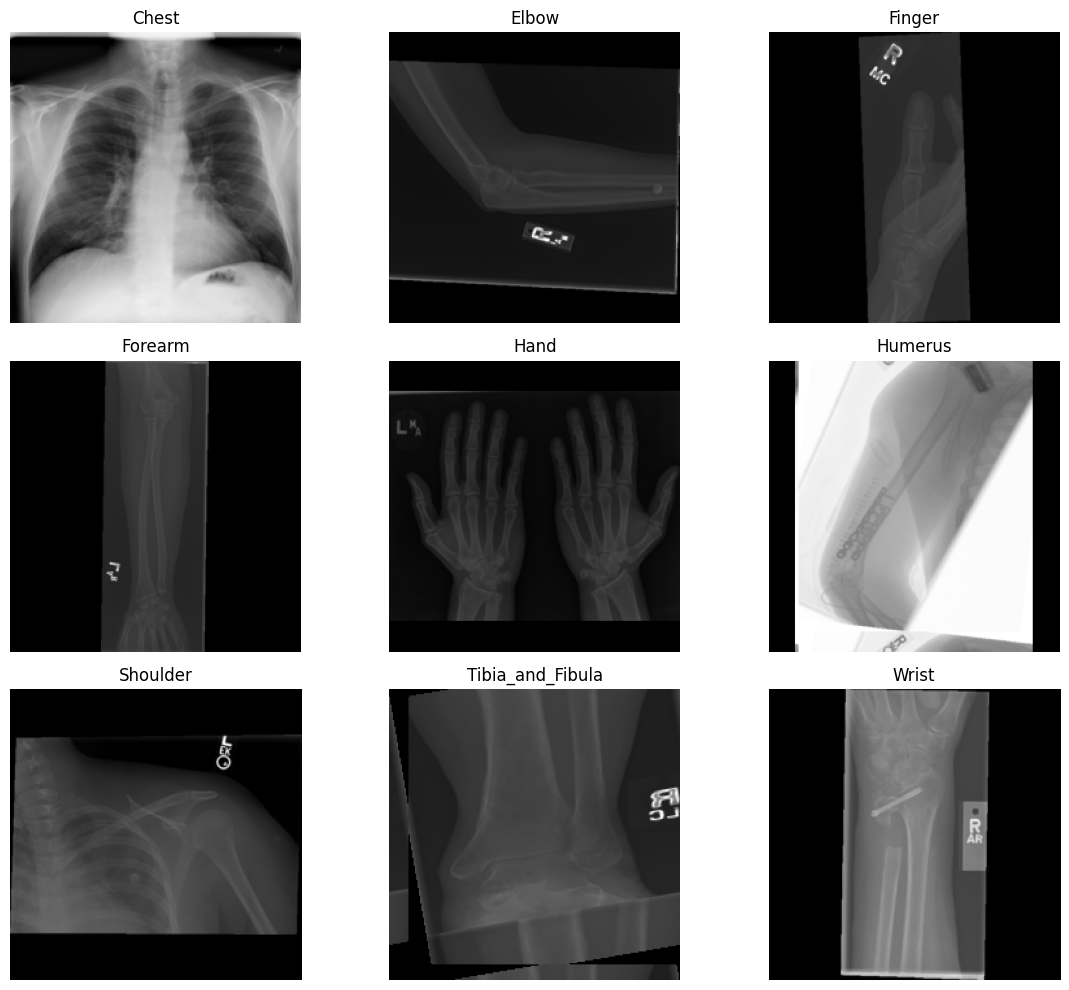


Note: If test images look very different from training images,
the discrepancy may be due to dataset shift or preprocessing differences.


In [ ]:
## Data Distribution Analysis (Diagnostic)

# Check class distribution in train, val, and test sets
from collections import Counter

train_labels = [row['label'] for row in dataset["train"]]
val_labels = [row['label'] for row in dataset["validation"]]
test_labels = [row['label'] for row in dataset["test"]]

train_counts = Counter(train_labels)
val_counts = Counter(val_labels)
test_counts = Counter(test_labels)

print("Class Distribution:")
print("\n" + "="*70)
print(f"{'Class':<20} {'Train':<15} {'Val':<15} {'Test':<15}")
print("="*70)

all_classes = set(train_counts.keys()) | set(val_counts.keys()) | set(test_counts.keys())
for cls in sorted(all_classes):
    train_pct = (train_counts[cls] / len(train_labels)) * 100 if cls in train_counts else 0
    val_pct = (val_counts[cls] / len(val_labels)) * 100 if cls in val_counts else 0
    test_pct = (test_counts[cls] / len(test_labels)) * 100 if cls in test_counts else 0
    
    print(f"{cls:<20} {train_counts[cls]:<6} ({train_pct:>5.1f}%) {val_counts[cls]:<6} ({val_pct:>5.1f}%) {test_counts[cls]:<6} ({test_pct:>5.1f}%)")

print("="*70)

# Visualize sample test images
print("\nSampling test images from each class...")
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.flatten()

test_by_class = {}
for idx, row in enumerate(dataset["test"]):
    label = row['label']
    if label not in test_by_class:
        test_by_class[label] = []
    test_by_class[label].append(idx)

for i, (cls, indices) in enumerate(sorted(test_by_class.items())[:9]):
    sample_idx = indices[0]
    sample = dataset["test"][sample_idx]
    axes[i].imshow(sample['image'], cmap='gray')
    axes[i].set_title(f"{cls}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

print("\nNote: If test images look very different from training images,")
print("the discrepancy may be due to dataset shift or preprocessing differences.")

Loading model and image processor...


Loading weights: 100%|██████████| 314/314 [00:00<00:00, 12721.43it/s]



Running inference on test set...


Testing: 100%|██████████| 85/85 [00:07<00:00, 11.62it/s]



Test Set Results
Test Loss: 0.1543
Test Accuracy: 0.9585
Precision: 0.9593
Recall: 0.9585
F1-Score: 0.9583


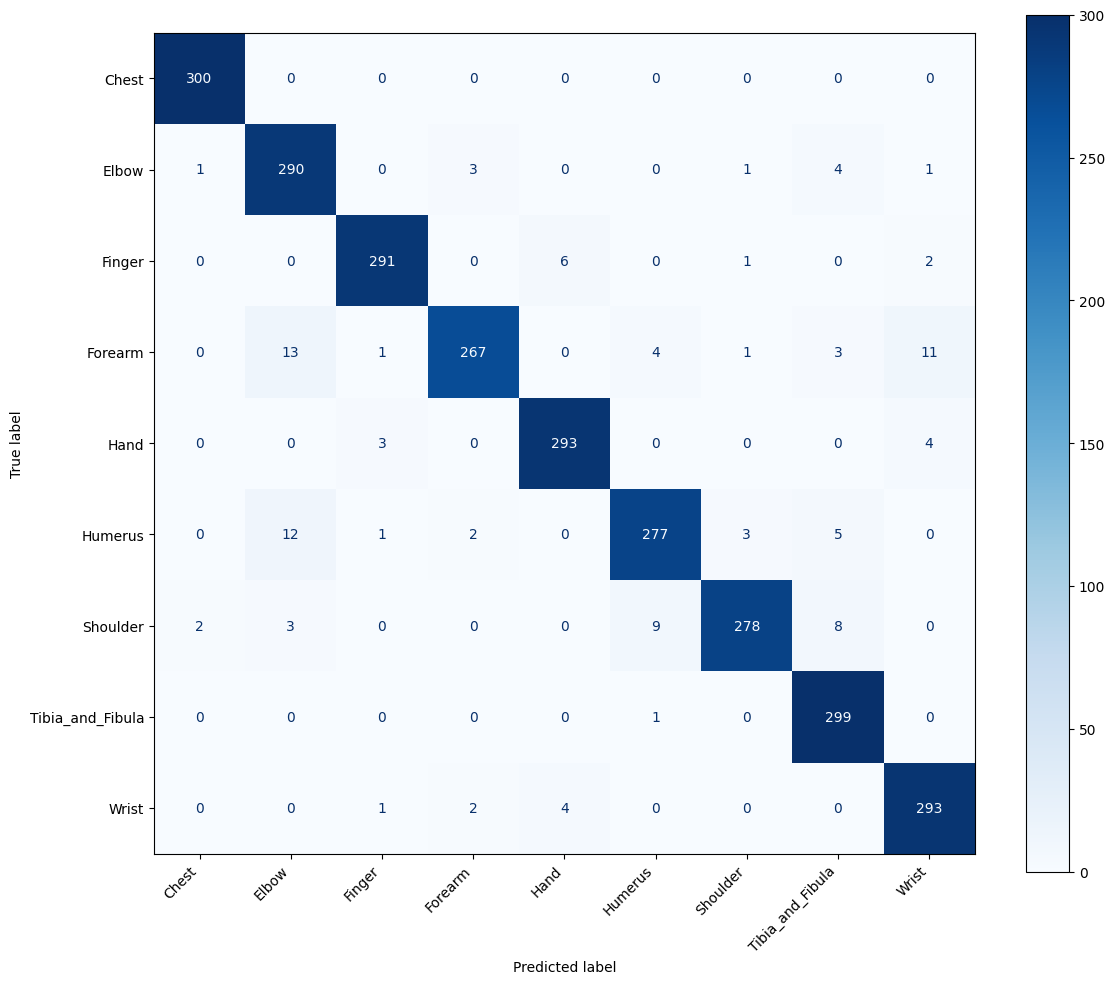


Test set evaluation complete!
[[300   0   0   0   0   0   0   0   0]
 [  1 290   0   3   0   0   1   4   1]
 [  0   0 291   0   6   0   1   0   2]
 [  0  13   1 267   0   4   1   3  11]
 [  0   0   3   0 293   0   0   0   4]
 [  0  12   1   2   0 277   3   5   0]
 [  2   3   0   0   0   9 278   8   0]
 [  0   0   0   0   0   1   0 299   0]
 [  0   0   1   2   4   0   0   0 293]]


In [ ]:
# Load the best model and image processor
from tqdm import tqdm
from transformers import AutoModelForImageClassification, AutoImageProcessor
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay

final_model_dir = notebook_folderPath / "output" / "final_model"

print("Loading model and image processor...")
loaded_model = AutoModelForImageClassification.from_pretrained(str(final_model_dir))
loaded_image_processor = AutoImageProcessor.from_pretrained(str(final_model_dir))
loaded_model.to(device)
loaded_model.eval()

# Run inference on test set
print("\nRunning inference on test set...")
all_predictions = []
all_labels = []
test_losses = []

with torch.no_grad():
    for batch in tqdm(test_dataloader, desc="Testing"):
        pixel_values = batch['pixel_values'].to(device)
        labels = batch['labels'].to(device)
        
        outputs = loaded_model(pixel_values=pixel_values, labels=labels)
        logits = outputs.logits
        loss = outputs.loss
        
        test_losses.append(loss.item())
        predictions = logits.argmax(-1)
        
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Convert to numpy arrays
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)
avg_test_loss = np.mean(test_losses)

# Calculate metrics
test_accuracy = accuracy_score(all_labels, all_predictions)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_predictions, average='weighted')

print(f"\n{'='*50}")
print(f"Test Set Results")
print(f"{'='*50}")
print(f"Test Loss: {avg_test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"{'='*50}")


cm = confusion_matrix(all_labels, all_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[id2label[i] for i in range(len(id2label))])
fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(ax=ax, cmap='Blues')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nTest set evaluation complete!")

print(cm)

In [ ]:
## Test Set Performance Analysis

# Detailed per-class analysis
print(f"\n{'='*70}")
print("Detailed Per-Class Test Performance")
print(f"{'='*70}")

from collections import defaultdict

# Group predictions by class
class_predictions = defaultdict(list)
class_ground_truth = defaultdict(list)

for pred, true in zip(all_predictions, all_labels):
    true_class = id2label[true]
    pred_class = id2label[pred]
    class_ground_truth[true_class].append(true)
    class_predictions[true_class].append(pred)

# Calculate per-class accuracy
print(f"\n{'Class':<20} {'Correct':<10} {'Total':<10} {'Accuracy':<12}")
print(f"{'-'*70}")

class_accuracies = {}
for cls in sorted(class_ground_truth.keys()):
    true_labels = np.array(class_ground_truth[cls])
    pred_labels = np.array(class_predictions[cls])
    correct = np.sum(true_labels == pred_labels)
    total = len(true_labels)
    accuracy = correct / total if total > 0 else 0
    class_accuracies[cls] = accuracy
    
    print(f"{cls:<20} {correct:<10} {total:<10} {accuracy:>10.1%}")

print(f"{'-'*70}")

# Identify worst performing classes
worst_classes = sorted(class_accuracies.items(), key=lambda x: x[1])[:3]
print(f"\n⚠️  Worst Performing Classes:")
for cls, acc in worst_classes:
    print(f"   {cls}: {acc:.1%}")

print(f"\n✓ Best Performing Classes:")
best_classes = sorted(class_accuracies.items(), key=lambda x: x[1], reverse=True)[:3]
for cls, acc in best_classes:
    print(f"   {cls}: {acc:.1%}")

# Check if there's a systematic pattern
print(f"\n{'='*70}")
print("Possible Issues to Investigate:")
print(f"{'='*70}")
if all(acc < 0.5 for acc in class_accuracies.values()):
    print("❌ Model performs poorly on ALL classes - likely model or training issue")
elif any(acc < 0.1 for acc in class_accuracies.values()):
    print("❌ Some classes have near-random performance - check data quality/distribution")
else:
    print("⚠️  Uneven class performance - some classes learned better than others")


Detailed Per-Class Test Performance

Class                Correct    Total      Accuracy    
----------------------------------------------------------------------
Chest                300        300            100.0%
Elbow                290        300             96.7%
Finger               291        300             97.0%
Forearm              267        300             89.0%
Hand                 293        300             97.7%
Humerus              277        300             92.3%
Shoulder             278        300             92.7%
Tibia_and_Fibula     299        300             99.7%
Wrist                293        300             97.7%
----------------------------------------------------------------------

⚠️  Worst Performing Classes:
   Forearm: 89.0%
   Humerus: 92.3%
   Shoulder: 92.7%

✓ Best Performing Classes:
   Chest: 100.0%
   Tibia_and_Fibula: 99.7%
   Hand: 97.7%

Possible Issues to Investigate:
⚠️  Uneven class performance - some classes learned better than others


In [ ]:
## Detailed Confusion Analysis

# Check what classes are being predicted
print("\n" + "="*70)
print("Prediction Distribution (What Model Actually Predicts)")
print("="*70)

unique_predictions = np.unique(all_predictions)
pred_counts = {}
for pred_id in unique_predictions:
    pred_name = id2label[pred_id]
    count = np.sum(all_predictions == pred_id)
    pred_counts[pred_name] = count
    print(f"{pred_name:<20}: {count:>4} predictions ({count/len(all_predictions)*100:>5.1f}%)")

print("\n" + "="*70)
print("Ground Truth Distribution (What Should Be Predicted)")
print("="*70)

for label_id in range(len(id2label)):
    label_name = id2label[label_id]
    count = np.sum(all_labels == label_id)
    print(f"{label_name:<20}: {count:>4} samples ({count/len(all_labels)*100:>5.1f}%)")

print("\n" + "="*70)
print("Confusion Matrix: Row = True Label, Column = Predicted Label")
print("="*70)

# Print confusion matrix in readable format
header = 'True \\ Pred'
print(f"\n{header:<15}", end='')
for i in range(len(id2label)):
    print(f"{id2label[i][:8]:<10}", end='')
print()

for i in range(len(id2label)):
    print(f"{id2label[i][:15]:<15}", end='')
    for j in range(len(id2label)):
        count = np.sum((all_labels == i) & (all_predictions == j))
        print(f"{count:<10}", end='')
    print()

# Identify which class is being over-predicted
print("\n" + "="*70)
print("Key Finding:")
print("="*70)
most_predicted = max(pred_counts.items(), key=lambda x: x[1])
print(f"Model is mostly predicting: {most_predicted[0]} ({most_predicted[1]} times out of {len(all_predictions)})")
print(f"This explains why only similar-looking classes perform well.")
print("\nPossible Causes:")
print("  1. Training data extremely imbalanced toward certain classes")
print("  2. Class weighting not applied during training")
print("  3. Data preprocessing differs between train/test sets")
print("  4. Test set contains different image characteristics")


Prediction Distribution (What Model Actually Predicts)
Chest               :  303 predictions ( 11.2%)
Elbow               :  318 predictions ( 11.8%)
Finger              :  297 predictions ( 11.0%)
Forearm             :  274 predictions ( 10.1%)
Hand                :  303 predictions ( 11.2%)
Humerus             :  291 predictions ( 10.8%)
Shoulder            :  284 predictions ( 10.5%)
Tibia_and_Fibula    :  319 predictions ( 11.8%)
Wrist               :  311 predictions ( 11.5%)

Ground Truth Distribution (What Should Be Predicted)
Chest               :  300 samples ( 11.1%)
Elbow               :  300 samples ( 11.1%)
Finger              :  300 samples ( 11.1%)
Forearm             :  300 samples ( 11.1%)
Hand                :  300 samples ( 11.1%)
Humerus             :  300 samples ( 11.1%)
Shoulder            :  300 samples ( 11.1%)
Tibia_and_Fibula    :  300 samples ( 11.1%)
Wrist               :  300 samples ( 11.1%)

Confusion Matrix: Row = True Label, Column = Predicted Label
